In [2]:
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt

In [4]:
def load_mnist_dataset(root: str = './data', save_dir: str = './mnist', download=True):
    """
    Function to load the MNIST dataset and save images as PNGs
    """
    import os
    from torchvision.utils import save_image
    from torch.utils.data import DataLoader
    
    # Create directories if they don't exist
    train_dir = os.path.join(save_dir, 'train')
    test_dir = os.path.join(save_dir, 'test')
    os.makedirs(train_dir, exist_ok=True)
    os.makedirs(test_dir, exist_ok=True)

    # Transform to tensor only (we'll save normalized images)
    transform = transforms.Compose([
        transforms.ToTensor(),
    ])

    # Load the MNIST dataset
    train_set = datasets.MNIST(root=root, train=True, download=download, transform=transform)
    test_set = datasets.MNIST(root=root, train=False, download=download, transform=transform)

    # Save training images
    print("Saving training images...")
    for idx, (image, _) in enumerate(train_set):
        save_image(image, os.path.join(train_dir, f'train_{idx:05d}.png'))
        if (idx + 1) % 1000 == 0:
            print(f"Saved {idx + 1} training images")

    # Save test images
    print("Saving test images...")
    for idx, (image, _) in enumerate(test_set):
        save_image(image, os.path.join(test_dir, f'test_{idx:05d}.png'))
        if (idx + 1) % 1000 == 0:
            print(f"Saved {idx + 1} test images")

    print("Done saving images!")
    
    # Return lists of file paths instead of images
    train_files = [os.path.join(train_dir, f) for f in sorted(os.listdir(train_dir))]
    test_files = [os.path.join(test_dir, f) for f in sorted(os.listdir(test_dir))]
    
    return train_files, test_files

In [5]:
train_files, test_files = load_mnist_dataset(save_dir='/workspace/generative-bridges/thirdparty/improved-diffusion/datasets/mnist')

Failed to download (trying next):
HTTP Error 403: Forbidden



100%|██████████| 9912422/9912422 [00:00<00:00, 11340289.11it/s]


Extracting ./data/MNIST/raw/train-images-idx3-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 403: Forbidden



100%|██████████| 28881/28881 [00:00<00:00, 13701582.83it/s]


Extracting ./data/MNIST/raw/train-labels-idx1-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 403: Forbidden



100%|██████████| 1648877/1648877 [00:00<00:00, 3537178.50it/s]


Extracting ./data/MNIST/raw/t10k-images-idx3-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 403: Forbidden



100%|██████████| 4542/4542 [00:00<00:00, 2090019.61it/s]


Extracting ./data/MNIST/raw/t10k-labels-idx1-ubyte.gz to ./data/MNIST/raw

Saving training images...
Saved 1000 training images
Saved 2000 training images
Saved 3000 training images
Saved 4000 training images
Saved 5000 training images
Saved 6000 training images
Saved 7000 training images
Saved 8000 training images
Saved 9000 training images
Saved 10000 training images
Saved 11000 training images
Saved 12000 training images
Saved 13000 training images
Saved 14000 training images
Saved 15000 training images
Saved 16000 training images
Saved 17000 training images
Saved 18000 training images
Saved 19000 training images
Saved 20000 training images
Saved 21000 training images
Saved 22000 training images
Saved 23000 training images
Saved 24000 training images
Saved 25000 training images
Saved 26000 training images
Saved 27000 training images
Saved 28000 training images
Saved 29000 training images
Saved 30000 training images
Saved 31000 training images
Saved 32000 training images
Saved 33000 

In [1]:
diff_imgs = '/workspace/aim-ddpm-img/mnist_steps_1000_openAI_100.npz'
imp_diff_imgs = '/tmp/openai-2025-01-12-18-00-33-225143/samples_600x28x28x3.npz'

In [4]:


# Load both NPZ files
diff_imgs = np.load('/workspace/aim-ddpm-img/mnist_steps_1000_openAI_100.npz')
imp_diff_imgs = np.load('/tmp/openai-2025-01-12-18-00-33-225143/samples_600x28x28x3.npz')

# Get the arrays (usually stored with key 'arr_0' if not named)
diff_samples = diff_imgs['images']
imp_samples = imp_diff_imgs['arr_0']

# Print shapes to compare
print("Original diffusion samples shape:", diff_samples.shape)
print("Improved diffusion samples shape:", imp_samples.shape)

Original diffusion samples shape: (100, 28, 28, 1)
Improved diffusion samples shape: (600, 28, 28, 3)


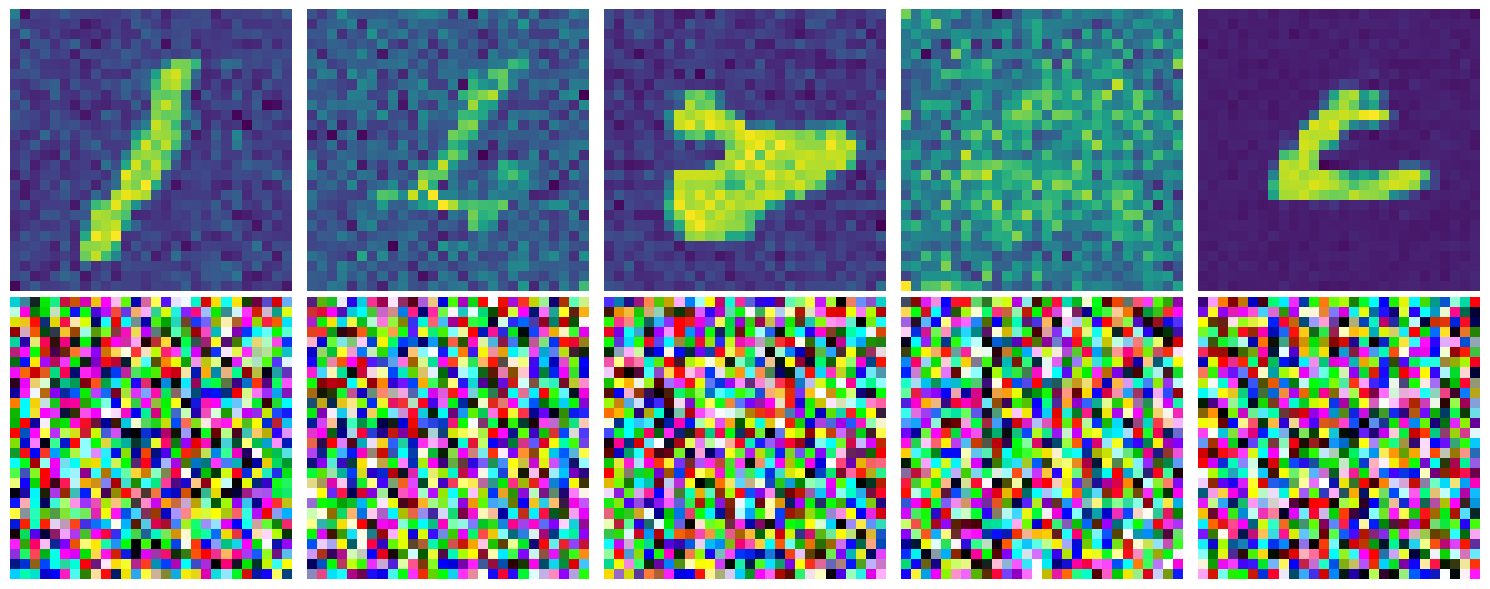

In [7]:
# Visualize a few samples from each
def plot_samples(samples1, samples2, num_samples=5):
    fig, axes = plt.subplots(2, num_samples, figsize=(15, 6))
    
    # Plot original diffusion samples
    for i in range(num_samples):
        if len(samples1.shape) == 4:  # If RGB
            axes[0, i].imshow(samples1[i])
        else:  # If grayscale
            axes[0, i].imshow(samples1[i], cmap='gray')
        axes[0, i].axis('off')
        
    # Plot improved diffusion samples
    for i in range(num_samples):
        if len(samples2.shape) == 4:  # If RGB
            axes[1, i].imshow(samples2[i])
        else:  # If grayscale
            axes[1, i].imshow(samples2[i], cmap='gray')
        axes[1, i].axis('off')
    
    axes[0, 0].set_ylabel('Original')
    axes[1, 0].set_ylabel('Improved')
    plt.tight_layout()
    plt.show()

# Plot 5 samples from each
plot_samples(diff_samples, imp_samples, num_samples=5)